In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

print("Libraries imported successfully")

Libraries imported successfully


In [86]:

dataset = pd.read_csv('/content/diabetes_binary_health_indicators_BRFSS2015.csv')

print(dataset.head())

   Diabetes_binary  HighBP  HighChol  CholCheck   BMI  Smoker  Stroke  \
0              0.0     1.0       1.0        1.0  40.0     1.0     0.0   
1              0.0     0.0       0.0        0.0  25.0     1.0     0.0   
2              0.0     1.0       1.0        1.0  28.0     0.0     0.0   
3              0.0     1.0       0.0        1.0  27.0     0.0     0.0   
4              0.0     1.0       1.0        1.0  24.0     0.0     0.0   

   HeartDiseaseorAttack  PhysActivity  Fruits  Veggies  HvyAlcoholConsump  \
0                   0.0           0.0     0.0      1.0                0.0   
1                   0.0           1.0     0.0      0.0                0.0   
2                   0.0           0.0     1.0      0.0                0.0   
3                   0.0           1.0     1.0      1.0                0.0   
4                   0.0           1.0     1.0      1.0                0.0   

   AnyHealthcare  NoDocbcCost  GenHlth  MentHlth  PhysHlth  DiffWalk  Sex  \
0            1.0     

In [87]:
print("Dataset Shape:", dataset.shape)

print("\nColumn Names:")
print(dataset.columns)

print("\nDataset Information:")
dataset.info()

print("\nStatistical Summary:")
print(dataset.describe())

Dataset Shape: (253680, 22)

Column Names:
Index(['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education',
       'Income'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseor

In [88]:
print(dataset.isnull().sum())

missing_percentage = (dataset.isnull().mean() * 100)

print("\nMissing Value Percentage:")
print(missing_percentage)

Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

Missing Value Percentage:
Diabetes_binary         0.0
HighBP                  0.0
HighChol                0.0
CholCheck               0.0
BMI                     0.0
Smoker                  0.0
Stroke                  0.0
HeartDiseaseorAttack    0.0
PhysActivity            0.0
Fruits                  0.0
Veggies                 0.0
HvyAlcoholConsump       0.0
AnyHealthcare           0.0
NoDocbcCost             

In [91]:
print("Duplicate Records:", dataset.duplicated().sum())

dataset = dataset.drop_duplicates()

dataset = dataset.reset_index(drop=True)

print("Shape after cleaning:", dataset.shape)

Duplicate Records: 0
Shape after cleaning: (229474, 22)


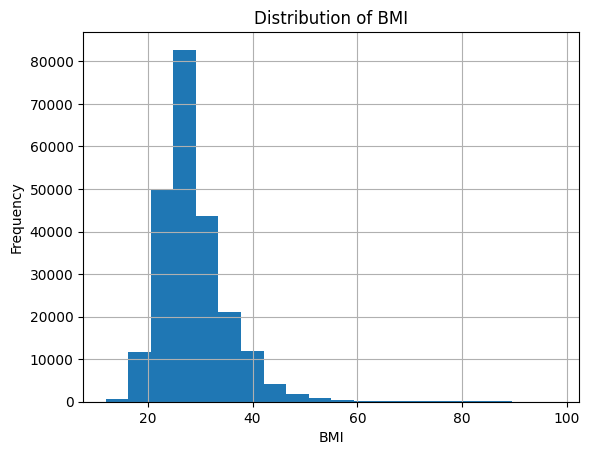

In [92]:
dataset["BMI"].hist(bins=20)

plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.title("Distribution of BMI")
plt.show()

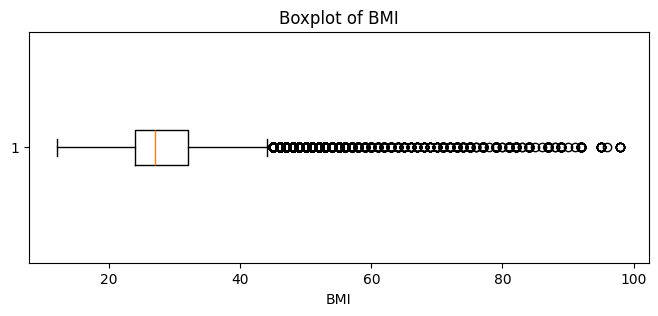

In [93]:
plt.figure(figsize=(8, 3))

plt.boxplot(dataset["BMI"].dropna(), vert=False)

plt.xlabel("BMI")
plt.title("Boxplot of BMI")
plt.show()

In [94]:
q1 = dataset["BMI"].quantile(0.25)
q3 = dataset["BMI"].quantile(0.75)

iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = dataset[
    (dataset["BMI"] < lower) |
    (dataset["BMI"] > upper)
]

print("Lower Limit:", lower)
print("Upper Limit:", upper)
print("Number of Outliers:", len(outliers))

Lower Limit: 12.0
Upper Limit: 44.0
Number of Outliers: 5638


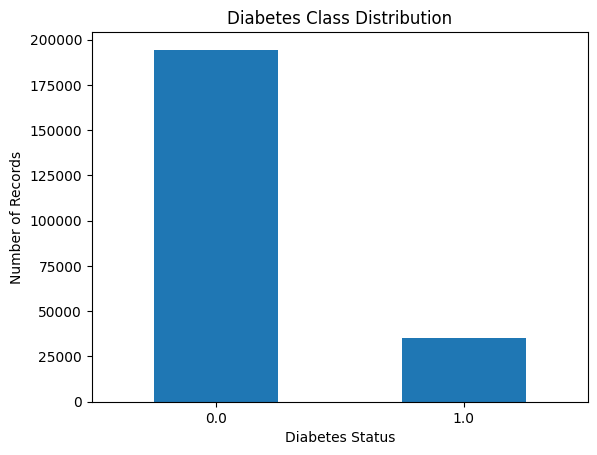

In [95]:
dataset["Diabetes_binary"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Diabetes Status")
plt.ylabel("Number of Records")
plt.title("Diabetes Class Distribution")
plt.xticks(rotation=0)
plt.show()

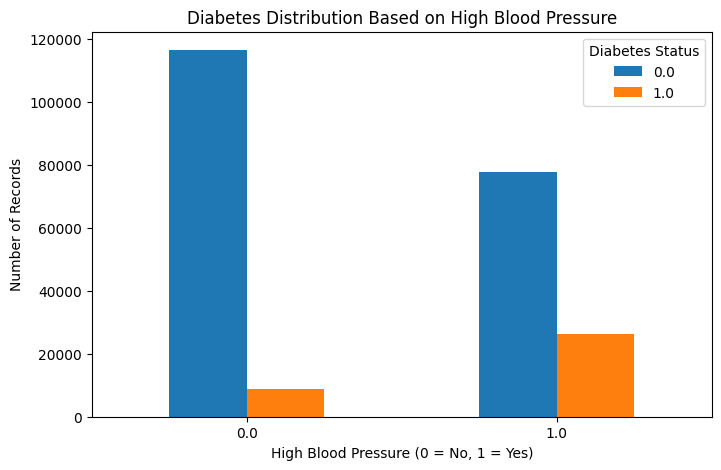

In [96]:
bp_diabetes = pd.crosstab(
    dataset['HighBP'],
    dataset['Diabetes_binary']
)

bp_diabetes.plot(kind='bar', figsize=(8,5))

plt.title("Diabetes Distribution Based on High Blood Pressure")
plt.xlabel("High Blood Pressure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.legend(title="Diabetes Status")
plt.xticks(rotation=0)

plt.show()

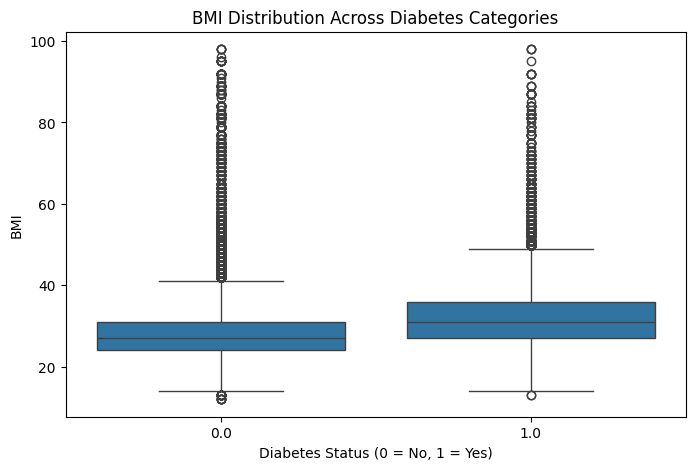

In [97]:
plt.figure(figsize=(8,5))

sns.boxplot(x='Diabetes_binary', y='BMI', data=dataset)

plt.title("BMI Distribution Across Diabetes Categories")
plt.xlabel("Diabetes Status (0 = No, 1 = Yes)")
plt.ylabel("BMI")

plt.show()

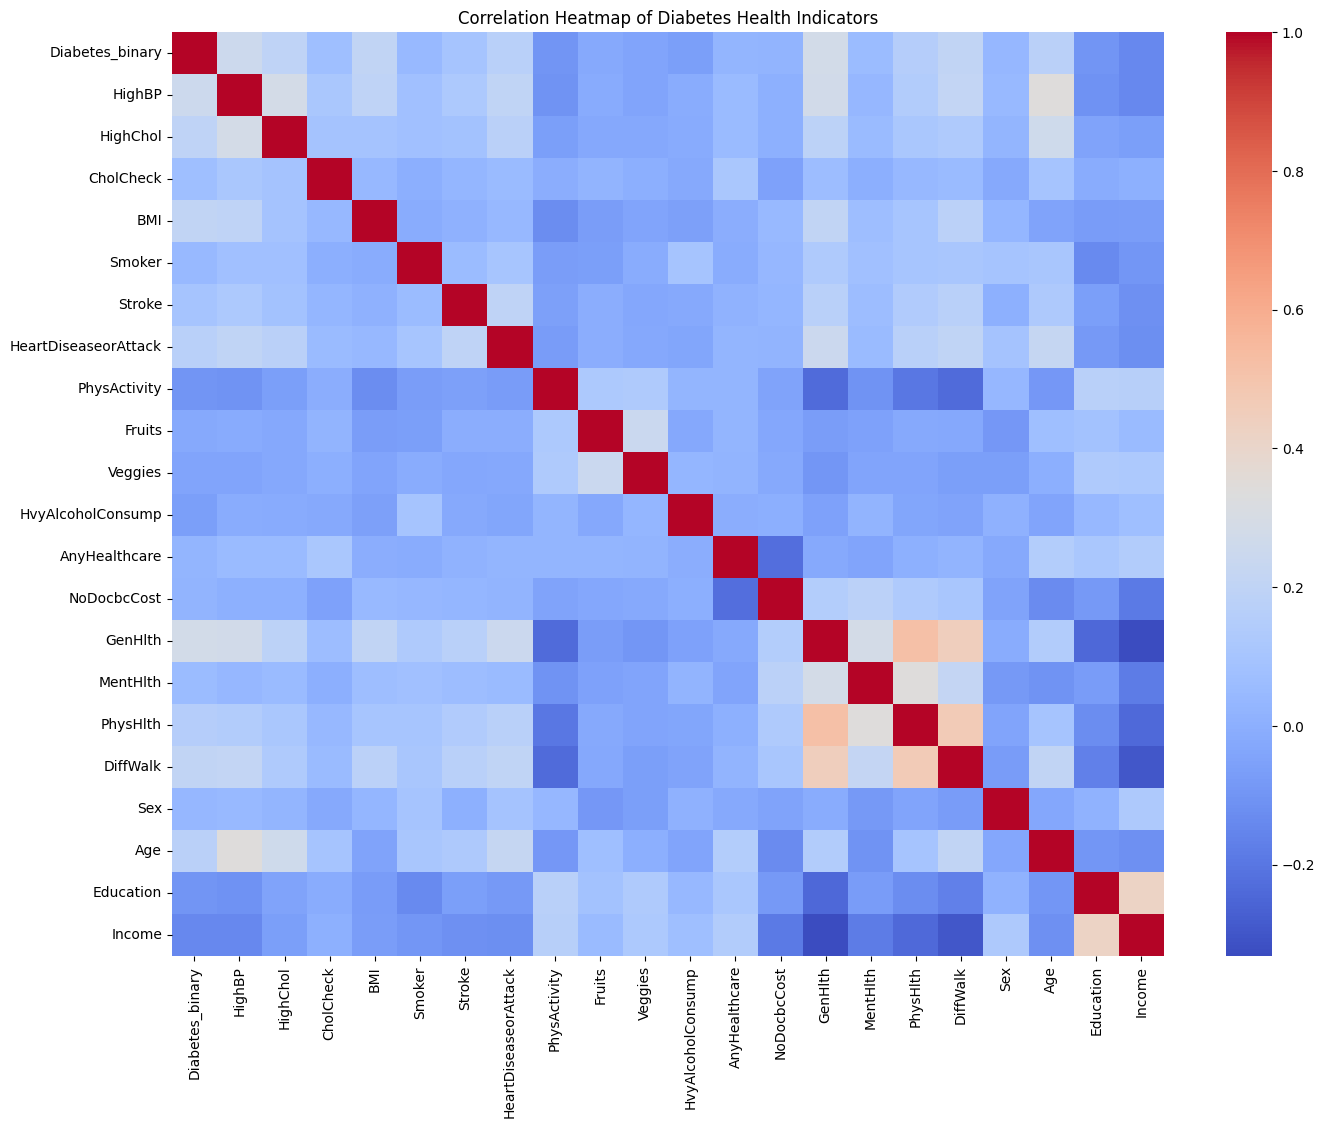

In [98]:
correlation = dataset.corr()

plt.figure(figsize=(16,12))

sns.heatmap(correlation, cmap='coolwarm', annot=False)

plt.title("Correlation Heatmap of Diabetes Health Indicators")
plt.show()

In [99]:
from scipy.stats import chi2_contingency

table = pd.crosstab(dataset['HighBP'], dataset['Diabetes_binary'])

chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-square Statistic:", chi2)
print("P-value:", p_value)

if p_value < 0.05:
    print("There is a statistically significant association.")
else:
    print("There is no statistically significant association.")

Chi-square Statistic: 14840.421805278642
P-value: 0.0
There is a statistically significant association.


In [100]:
target_correlation = dataset.corr()['Diabetes_binary'].sort_values(ascending=False)

print("Correlation of Features with Diabetes:")
print(target_correlation)

Correlation of Features with Diabetes:
Diabetes_binary         1.000000
GenHlth                 0.276940
HighBP                  0.254318
DiffWalk                0.205302
BMI                     0.205086
HighChol                0.194944
Age                     0.177263
HeartDiseaseorAttack    0.168213
PhysHlth                0.156211
Stroke                  0.099193
CholCheck               0.072523
MentHlth                0.054153
Smoker                  0.045504
Sex                     0.032724
AnyHealthcare           0.025331
NoDocbcCost             0.020048
Fruits                 -0.024805
Veggies                -0.041734
HvyAlcoholConsump      -0.065950
PhysActivity           -0.100404
Education              -0.102686
Income                 -0.140659
Name: Diabetes_binary, dtype: float64


In [101]:
health_analysis = dataset.groupby(
    ['HighBP', 'HighChol']
)['Diabetes_binary'].mean() * 100

print("Percentage of Diabetes Records:")
print(health_analysis)

Percentage of Diabetes Records:
HighBP  HighChol
0.0     0.0          4.935717
        1.0         11.345310
1.0     0.0         17.469064
        1.0         30.648197
Name: Diabetes_binary, dtype: float64


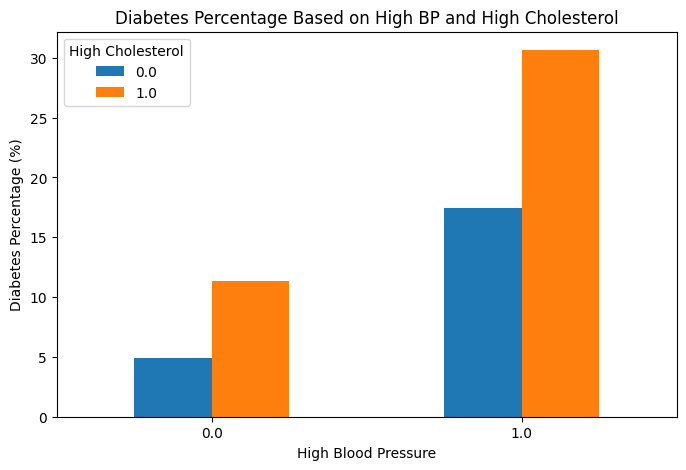

In [102]:
health_analysis.unstack().plot(
    kind='bar',
    figsize=(8,5)
)

plt.title("Diabetes Percentage Based on High BP and High Cholesterol")
plt.xlabel("High Blood Pressure")
plt.ylabel("Diabetes Percentage (%)")

plt.legend(title="High Cholesterol")
plt.xticks(rotation=0)

plt.show()

In [103]:
from scipy.stats import ttest_ind

diabetes_group = dataset[dataset['Diabetes_binary'] == 1]['BMI']
non_diabetes_group = dataset[dataset['Diabetes_binary'] == 0]['BMI']

t_stat, p_value = ttest_ind(
    diabetes_group,
    non_diabetes_group,
    equal_var=False
)

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("There is a significant difference in mean BMI.")
else:
    print("There is no significant difference in mean BMI.")

T-Statistic: 91.95949548256084
P-Value: 0.0
There is a significant difference in mean BMI.


In [104]:
print("Average BMI of Non-Diabetic Respondents:",
      non_diabetes_group.mean())

print("Average BMI of Diabetic Respondents:",
      diabetes_group.mean())

Average BMI of Non-Diabetic Respondents: 28.095854962264053
Average BMI of Diabetic Respondents: 31.96424195800211


In [105]:
X = dataset.drop('Diabetes_binary', axis=1).values
y = dataset['Diabetes_binary'].values

print("Independent Variables Shape:", X.shape)
print("Dependent Variable Shape:", y.shape)

Independent Variables Shape: (229474, 21)
Dependent Variable Shape: (229474,)


In [106]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (183579, 21)
X_test: (45895, 21)
y_train: (183579,)
y_test: (45895,)


In [107]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

X_train = sc.fit_transform(X_train)

X_test = sc.transform(X_test)

print("Feature Scaling Completed Successfully")

Feature Scaling Completed Successfully


In [108]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train, y_train)

y_pred_base = baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, y_pred_base)

print("Baseline Accuracy:", baseline_accuracy)

Baseline Accuracy: 0.8470639503213858


In [109]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()

lin_reg.fit(X_train, y_train)

y_pred_lr = lin_reg.predict(X_test)

y_pred_lr_class = (y_pred_lr >= 0.5).astype(int)

print("Linear Regression Training Completed")
print("Predicted Values:", y_pred_lr[:10])
print("Predicted Classes:", y_pred_lr_class[:10])

Linear Regression Training Completed
Predicted Values: [ 0.18004782 -0.06219077  0.2090187   0.20328139  0.06789103  0.2496651
  0.15297984  0.29241617 -0.03530168  0.06026484]
Predicted Classes: [0 0 0 0 0 0 0 0 0 0]


In [110]:
from sklearn.linear_model import LogisticRegression

classifier = LogisticRegression(max_iter=1000)

classifier.fit(X_train, y_train)

y_pred_lr_log = classifier.predict(X_test)

print("Logistic Regression Training Completed")

Logistic Regression Training Completed


In [111]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

k_values = [3, 5, 7, 9, 11]

best_score = 0
best_k = None

for k in k_values:

    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_new, y_train_new)

    y_val_pred = knn.predict(X_val)

    score = f1_score(y_val, y_val_pred)

    print("K Value:", k)
    print("F1 Score:", score)

    if score > best_score:
        best_score = score
        best_k = k

print("\nBest K Value:", best_k)
print("Best F1 Score:", best_score)


K Value: 3
F1 Score: 0.2924943627187802
K Value: 5
F1 Score: 0.2754462702447098
K Value: 7
F1 Score: 0.25952291744723366
K Value: 9
F1 Score: 0.2387434554973822
K Value: 11
F1 Score: 0.2331222207249697

Best K Value: 3
Best F1 Score: 0.2924943627187802


In [112]:
from sklearn.neighbors import KNeighborsClassifier

knn_classifier = KNeighborsClassifier(n_neighbors=best_k)

knn_classifier.fit(X_train, y_train)

print("KNN Training Completed")

KNN Training Completed


In [113]:
y_pred_knn = knn_classifier.predict(X_test)

print("KNN Predictions:", y_pred_knn[:10])

KNN Predictions: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [114]:
X_dt = dataset.drop('Diabetes_binary', axis=1)
y_dt = dataset['Diabetes_binary']


X_train_dt, X_test_dt, y_train_dt, y_test_dt = train_test_split(
    X_dt, y_dt,
    test_size=0.2,
    random_state=42,
    stratify=y_dt
)

print("Decision Tree Training Shape:", X_train_dt.shape)
print("Decision Tree Testing Shape:", X_test_dt.shape)

Decision Tree Training Shape: (183579, 21)
Decision Tree Testing Shape: (45895, 21)


In [115]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train_dt, y_train_dt,
    test_size=0.2,
    random_state=42,
    stratify=y_train_dt
)

depth_values = [3, 5, 10, 15, None]

best_score = 0
best_depth = None

for depth in depth_values:

    model = DecisionTreeClassifier(
        criterion='entropy',
        max_depth=depth,
        random_state=0
    )

    model.fit(X_train_new, y_train_new)

    y_val_pred = model.predict(X_val)

    score = f1_score(y_val, y_val_pred)

    print("Max Depth:", depth)
    print("F1 Score:", score)

    if score > best_score:
        best_score = score
        best_depth = depth

print("\nBest Max Depth:", best_depth)
print("Best F1 Score:", best_score)


Max Depth: 3
F1 Score: 0.0
Max Depth: 5
F1 Score: 0.22529982866933182
Max Depth: 10
F1 Score: 0.24402376675417992
Max Depth: 15
F1 Score: 0.2684003340093045
Max Depth: None
F1 Score: 0.29926256216772423

Best Max Depth: None
Best F1 Score: 0.29926256216772423


In [116]:
from sklearn.tree import DecisionTreeClassifier

dt_classifier = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=best_depth,
    random_state=0
)

dt_classifier.fit(X_train_dt, y_train_dt)

print("Decision Tree Training Completed")

Decision Tree Training Completed


In [117]:
y_pred_dt = dt_classifier.predict(X_test_dt)

print("Decision Tree Predictions:", y_pred_dt[:10])

Decision Tree Predictions: [0. 0. 1. 0. 0. 1. 0. 1. 0. 0.]


In [118]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [119]:

results = []

models = {
    "Linear Regression": y_pred_lr_class,
    "Logistic Regression": y_pred_lr_log,
    "Decision Tree": y_pred_dt,
    "KNN": y_pred_knn
}

for name, prediction in models.items():

    accuracy = accuracy_score(y_test, prediction)
    precision = precision_score(y_test, prediction, zero_division=0)
    recall = recall_score(y_test, prediction, zero_division=0)
    f1 = f1_score(y_test, prediction, zero_division=0)

    print("\nModel:", name)
    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1 Score:", f1)

    print("\nClassification Report:")
    print(classification_report(y_test, prediction, zero_division=0))

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })
results.append({
    "Model": "Baseline",
    "Accuracy": baseline_accuracy,
    "Precision": 0,
    "Recall": 0,
    "F1 Score": 0
})



Model: Linear Regression
Accuracy: 0.8491338925808911
Precision: 0.5991649269311065
Recall: 0.04088901552927768
F1 Score: 0.07655374766604428

Classification Report:
              precision    recall  f1-score   support

         0.0       0.85      1.00      0.92     38876
         1.0       0.60      0.04      0.08      7019

    accuracy                           0.85     45895
   macro avg       0.73      0.52      0.50     45895
weighted avg       0.81      0.85      0.79     45895


Model: Logistic Regression
Accuracy: 0.8505283799978212
Precision: 0.5397698849424712
Recall: 0.15372560193759796
F1 Score: 0.2392991794189399

Classification Report:
              precision    recall  f1-score   support

         0.0       0.86      0.98      0.92     38876
         1.0       0.54      0.15      0.24      7019

    accuracy                           0.85     45895
   macro avg       0.70      0.57      0.58     45895
weighted avg       0.81      0.85      0.81     45895


Model: Dec

Logistic Regression ROC-AUC: 0.8101892136847084
KNN ROC-AUC: 0.6695698402060428
Decision Tree ROC-AUC: 0.5904036786016454


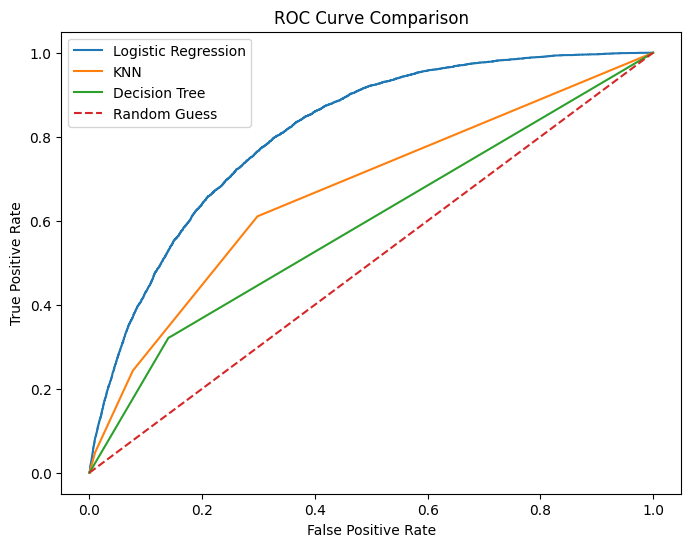

In [120]:
from sklearn.metrics import roc_auc_score, roc_curve

y_prob_log = classifier.predict_proba(X_test)[:, 1]
y_prob_knn = knn_classifier.predict_proba(X_test)[:, 1]
y_prob_dt = dt_classifier.predict_proba(X_test_dt)[:, 1]

# Calculate ROC-AUC scores
auc_log = roc_auc_score(y_test, y_prob_log)
auc_knn = roc_auc_score(y_test, y_prob_knn)
auc_dt = roc_auc_score(y_test, y_prob_dt)

print("Logistic Regression ROC-AUC:", auc_log)
print("KNN ROC-AUC:", auc_knn)
print("Decision Tree ROC-AUC:", auc_dt)

# Plot ROC curves
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)

plt.figure(figsize=(8, 6))

plt.plot(fpr_log, tpr_log, label='Logistic Regression')
plt.plot(fpr_knn, tpr_knn, label='KNN')
plt.plot(fpr_dt, tpr_dt, label='Decision Tree')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guess')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()


Decision Tree Feature Importance:


,Feature,Importance
3,BMI,0.140988
18,Age,0.108959
20,Income,0.102590
15,PhysHlth,0.091395
0,HighBP,0.078757
19,Education,0.075010
14,MentHlth,0.067454
13,GenHlth,0.062989
4,Smoker,0.037265
8,Fruits,0.036579


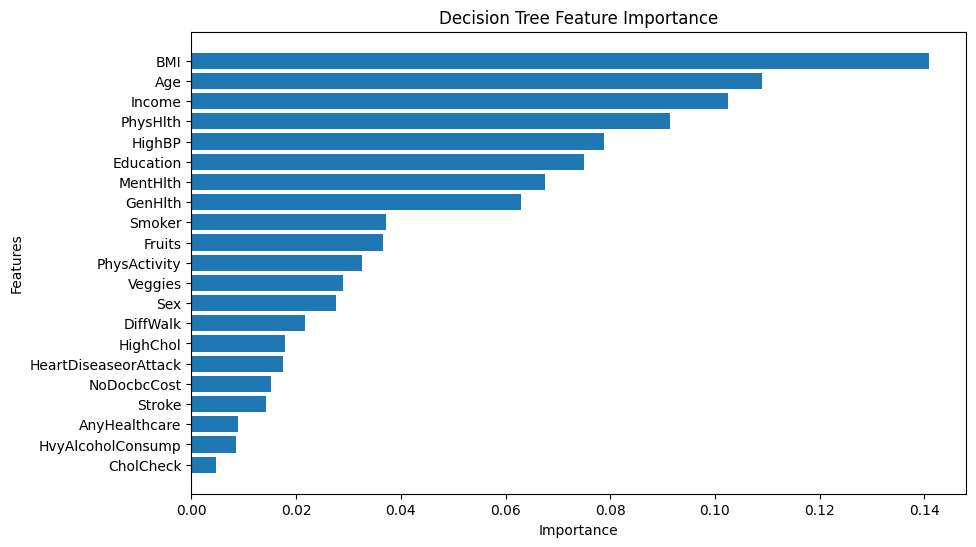

In [121]:
feature_importance = dt_classifier.feature_importances_

importance_df = pd.DataFrame({
    'Feature': dataset.drop('Diabetes_binary', axis=1).columns,
    'Importance': feature_importance
})


importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("Decision Tree Feature Importance:")
display(importance_df)


plt.figure(figsize=(10, 6))
plt.barh(
    importance_df['Feature'],
    importance_df['Importance']
)

plt.xlabel('Importance')
plt.ylabel('Features')
plt.title('Decision Tree Feature Importance')
plt.gca().invert_yaxis()
plt.show()


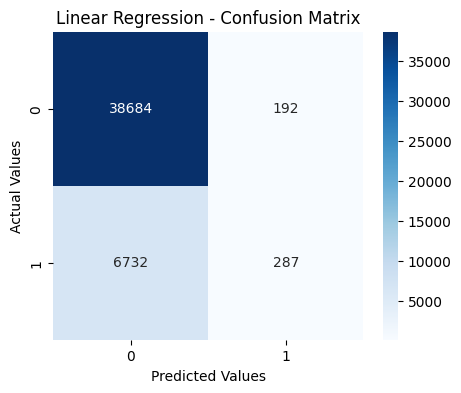

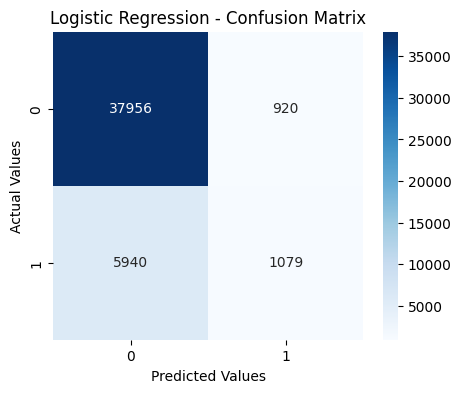

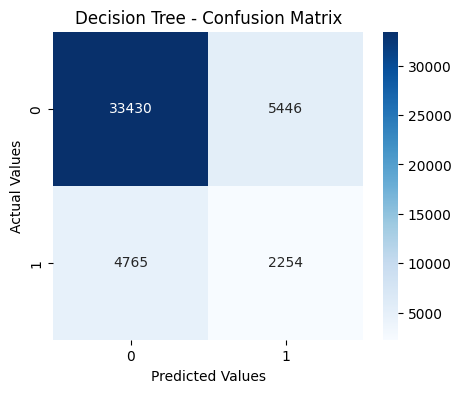

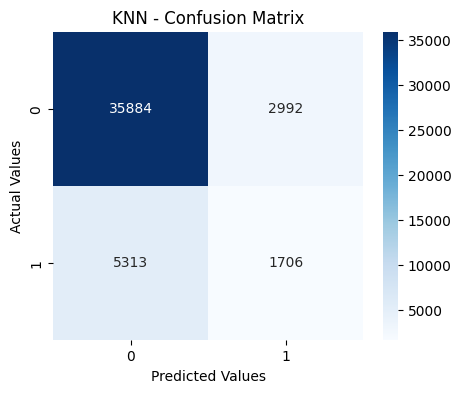

In [122]:
import matplotlib.pyplot as plt
import seaborn as sns

for name, prediction in models.items():

    cm = confusion_matrix(y_test, prediction)

    plt.figure(figsize=(5,4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted Values")
    plt.ylabel("Actual Values")

    plt.show()

In [123]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_lr)
mse = mean_squared_error(y_test, y_pred_lr)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Evaluation")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-Squared:", r2)

Linear Regression Evaluation
MAE: 0.2338333377834123
MSE: 0.10918886577263937
RMSE: 0.3304373855553263
R-Squared: 0.15714612621068047


In [83]:
comparison = pd.DataFrame(results)

print("FINAL MODEL COMPARISON")
display(comparison.sort_values(by="Accuracy", ascending=False))

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
1,Logistic Regression,0.850528,0.539770,0.153726,0.239299
0,Linear Regression,0.849134,0.599165,0.040889,0.076554
4,Baseline,0.847064,0.000000,0.000000,0.000000
3,KNN,0.819043,0.363133,0.243055,0.291201
2,Decision Tree,0.777514,0.292727,0.321128,0.306271


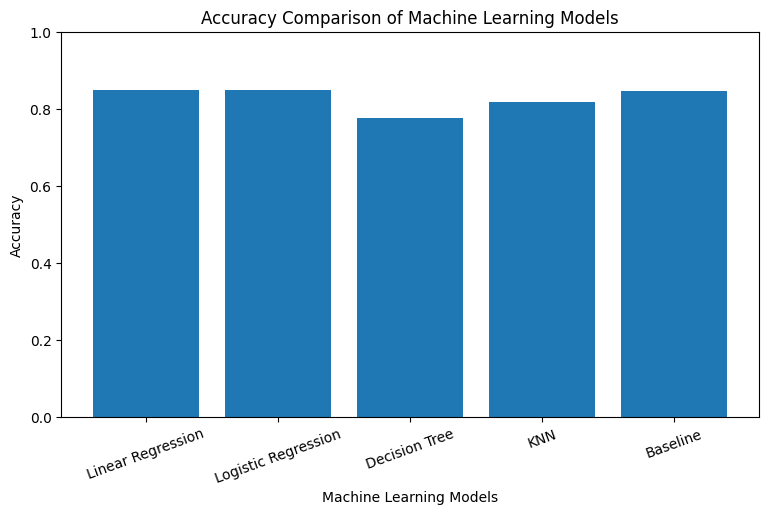

In [84]:
plt.figure(figsize=(9, 5))

plt.bar(comparison["Model"], comparison["Accuracy"])

plt.title("Accuracy Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.ylim(0, 1)

plt.show()